This notebook contains the Replication of the works of Corcoran & Jones (2022)

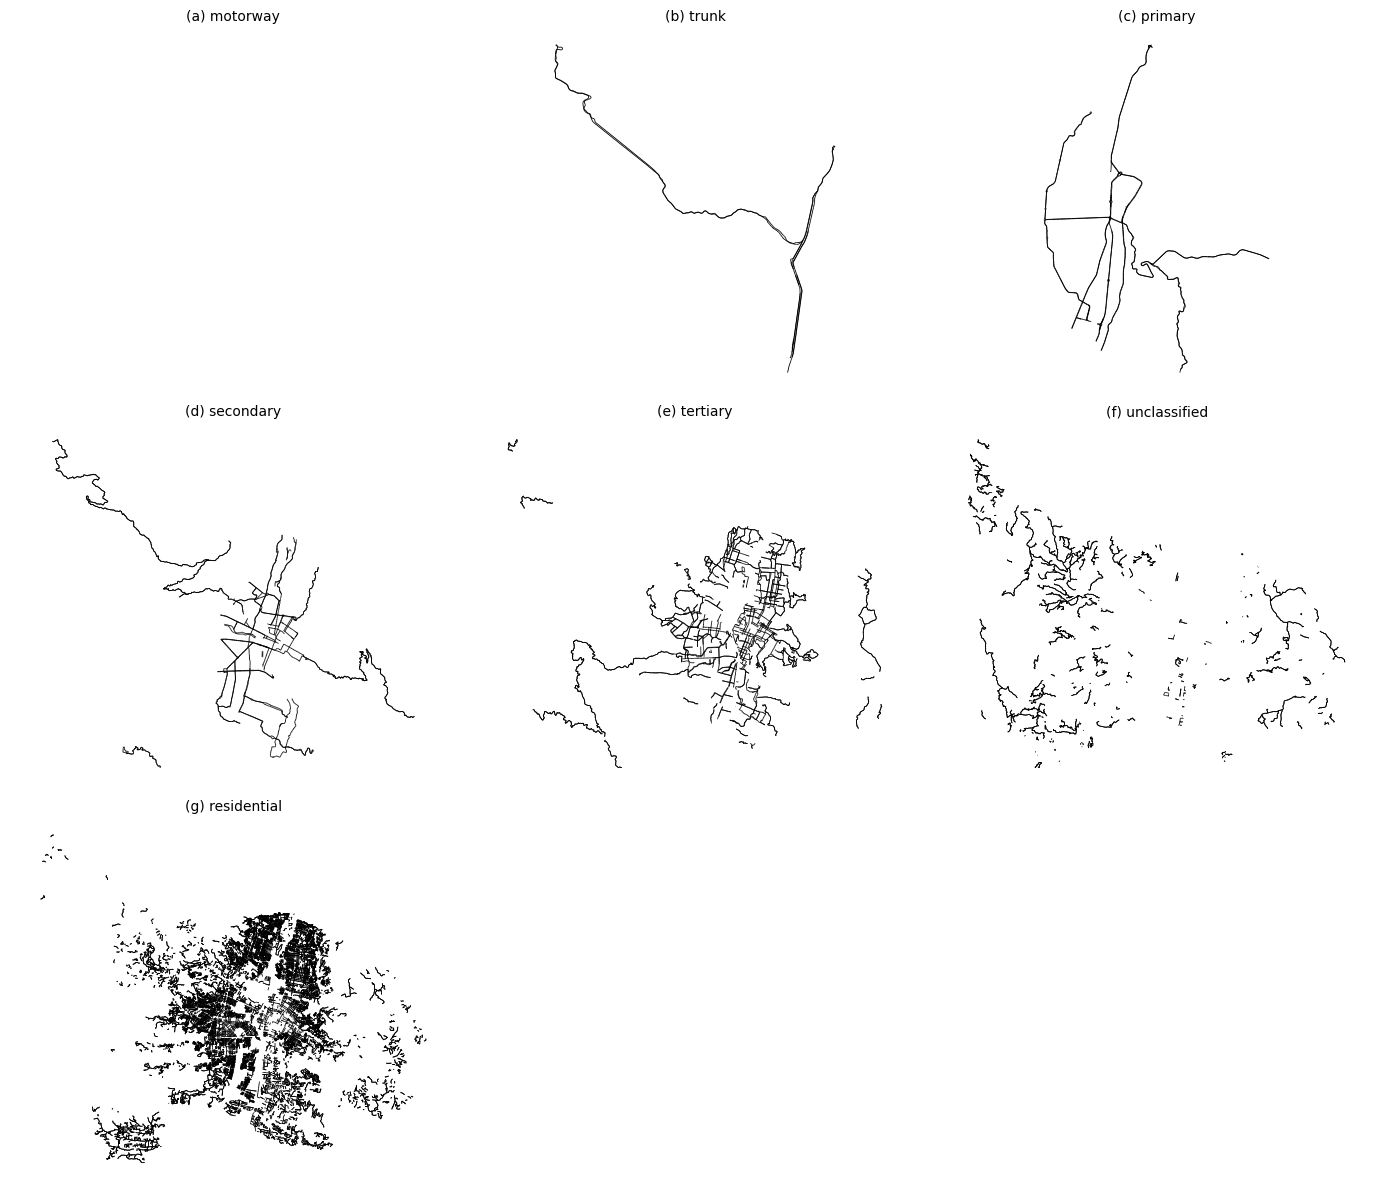

In [1]:
# pip install osmnx matplotlib

import osmnx as ox
import matplotlib.pyplot as plt
import geopandas as gpd

# -----------------------------
# 1. SETTINGS
# -----------------------------
place = "Medellín, Antioquia, Colombia"

highway_order = [
    "motorway",
    "trunk",
    "primary",
    "secondary",
    "tertiary",
    "unclassified",
    "residential",
]

ox.settings.use_cache = True
ox.settings.log_console = True

# -----------------------------
# 2. DOWNLOAD FULL STREET GRAPH
# -----------------------------
G = ox.graph_from_place(place, network_type="all", simplify=True)

# Convert to GeoDataFrame (edges only)
edges = ox.graph_to_gdfs(G, nodes=False)

# Some highways are stored as lists → normalize
edges["highway"] = edges["highway"].apply(
    lambda x: x[0] if isinstance(x, list) else x
)

# -----------------------------
# 3. PLOT EACH HIGHWAY TYPE
# -----------------------------
n = len(highway_order)
cols = 3
rows = int((n / cols) + 0.999)

fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows))
axes = axes.flatten()

for i, hw in enumerate(highway_order):
    ax = axes[i]

    subset = edges[edges["highway"] == hw]

    if not subset.empty:
        subset.plot(
            ax=ax,
            linewidth=0.6,
            color="black",
        )

    ax.set_title(f"({chr(97+i)}) {hw}", fontsize=10)
    ax.set_axis_off()

# Remove extra axes if any
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()




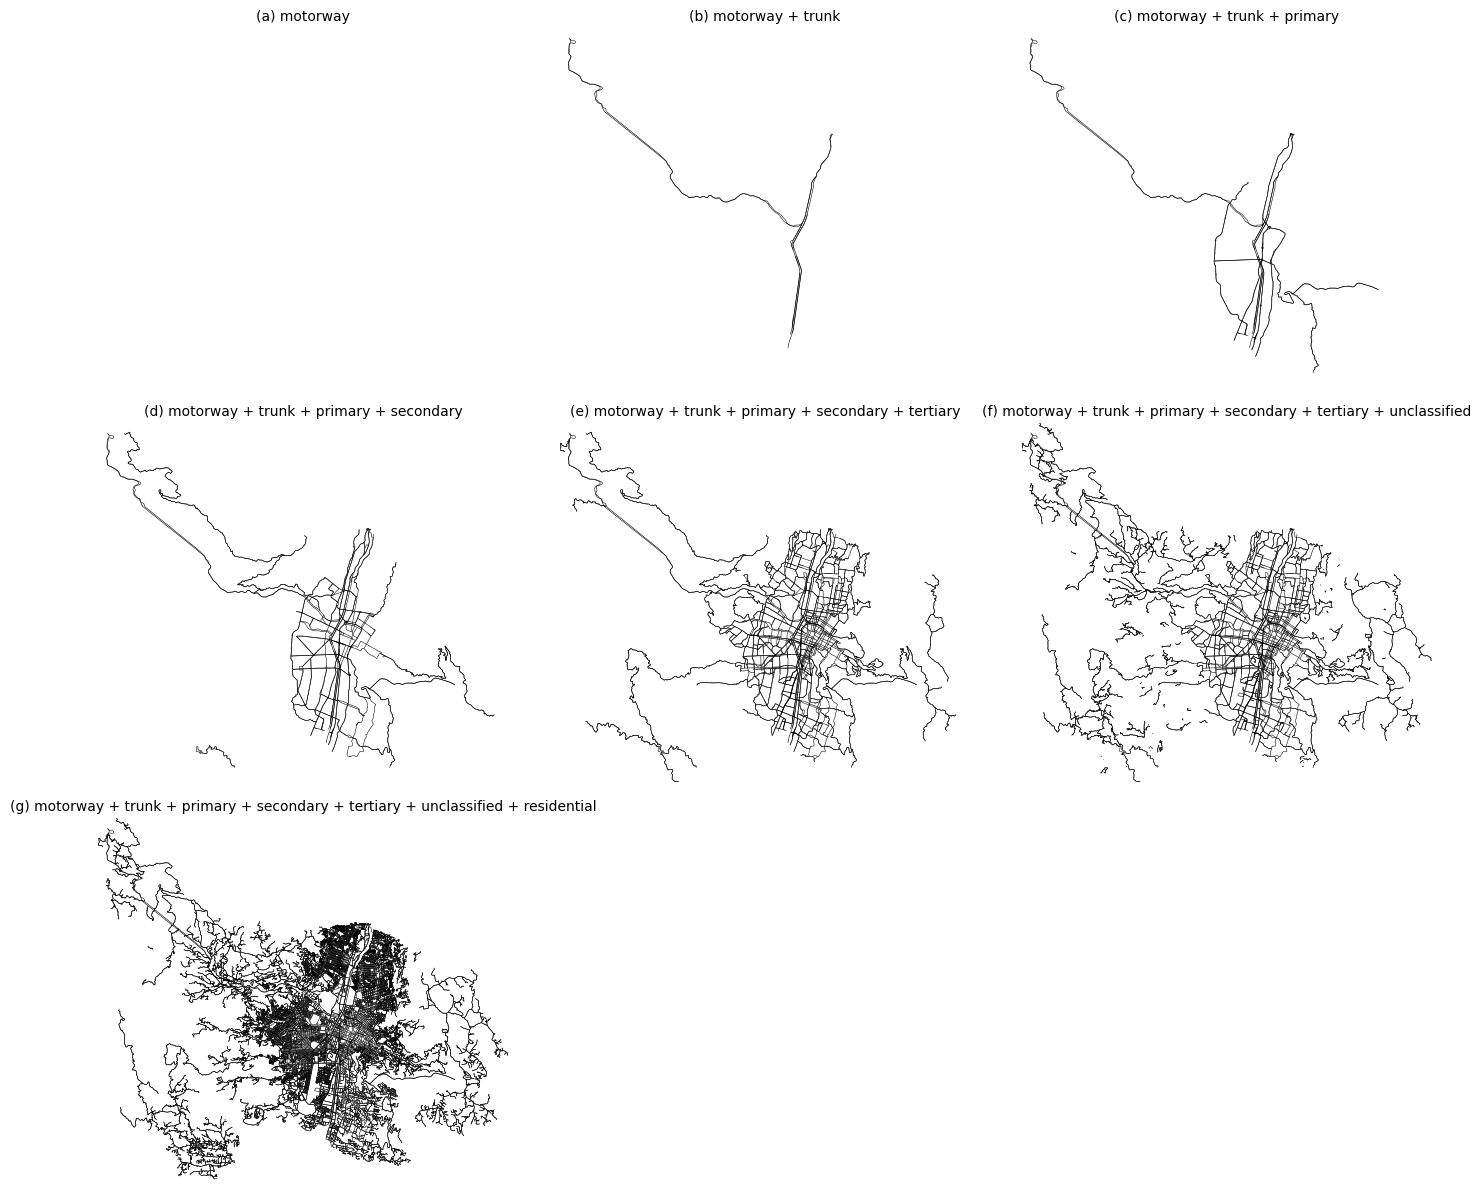

Final graph summary
Nodes: 29392
Edges: 36331

Simplex tree summary
Dimension: 1
Num vertices: 29392
Num simplices: 65723

Finite H1 intervals:
[]

Graph-theoretic diagnostics
Connected components: 34
Cycle rank: 6973

Betti numbers:
[34, 6973]


/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/gudhi/persistence_graphical_tools.py:129: UserWarning: usetex mode requires TeX.
  warnings.warn("usetex mode requires TeX.")


<Figure size 700x600 with 0 Axes>

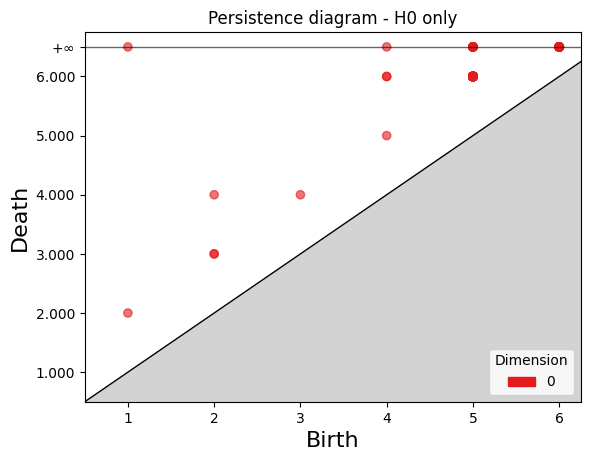

<Figure size 1000x400 with 0 Axes>

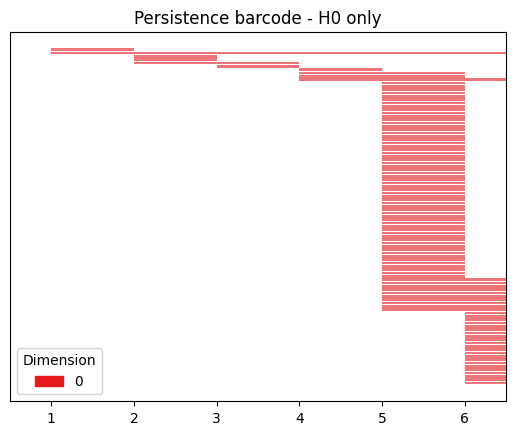

<Figure size 700x600 with 0 Axes>

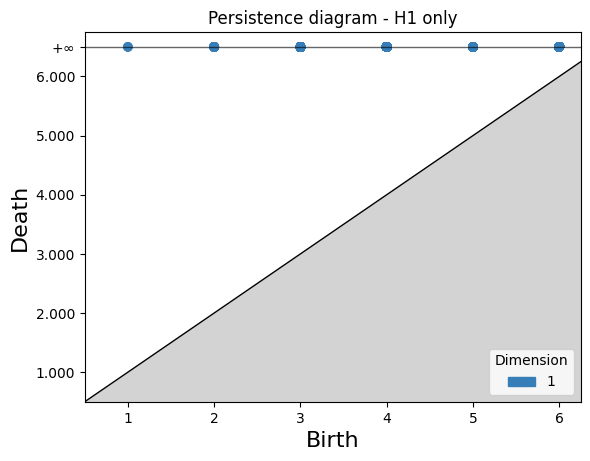

<Figure size 1000x400 with 0 Axes>

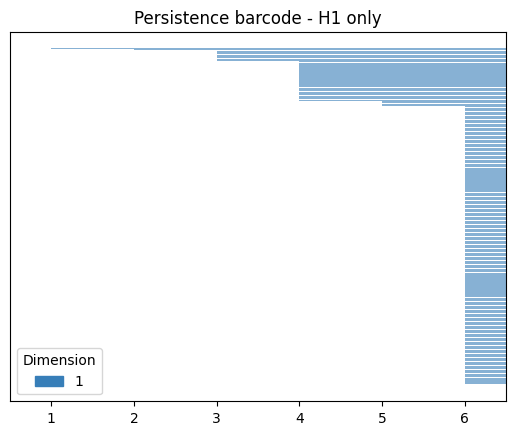


Step-by-step filtration summary

Step 0 -> ['motorway']
Nodes: 0
Edges: 0
Connected components: 0
Cycle rank: 0

Step 1 -> ['motorway', 'trunk']
Nodes: 421
Edges: 423
Connected components: 2
Cycle rank: 4

Step 2 -> ['motorway', 'trunk', 'primary']
Nodes: 2007
Edges: 2043
Connected components: 4
Cycle rank: 40

Step 3 -> ['motorway', 'trunk', 'primary', 'secondary']
Nodes: 5645
Edges: 5897
Connected components: 3
Cycle rank: 255

Step 4 -> ['motorway', 'trunk', 'primary', 'secondary', 'tertiary']
Nodes: 12061
Edges: 13143
Connected components: 5
Cycle rank: 1087

Step 5 -> ['motorway', 'trunk', 'primary', 'secondary', 'tertiary', 'unclassified']
Nodes: 13477
Edges: 14588
Connected components: 73
Cycle rank: 1184

Step 6 -> ['motorway', 'trunk', 'primary', 'secondary', 'tertiary', 'unclassified', 'residential']
Nodes: 29392
Edges: 36331
Connected components: 34
Cycle rank: 6973


In [2]:
import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import gudhi

# -----------------------------
# SETTINGS
# -----------------------------
place = "Medellín, Antioquia, Colombia"

highway_order = [
    "motorway",
    "trunk",
    "primary",
    "secondary",
    "tertiary",
    "unclassified",
    "residential",
]

filtration_time = {hw: i for i, hw in enumerate(highway_order)}

ox.settings.use_cache = True
ox.settings.log_console = True

# -----------------------------
# DOWNLOAD FULL NETWORK
# -----------------------------
G = ox.graph_from_place(place, network_type="all", simplify=True)

edges = ox.graph_to_gdfs(G, nodes=False).copy()

# Normalize highway field
def normalize_highway(x):
    if isinstance(x, list):
        return x[0]
    return x

edges["highway"] = edges["highway"].apply(normalize_highway)

# Keep only classes used in the filtration
edges = edges[edges["highway"].isin(highway_order)].copy()

# Global bounds for plotting
xmin, ymin, xmax, ymax = edges.total_bounds

# -----------------------------
# PLOT FILTRATION SNAPSHOTS
# -----------------------------
n = len(highway_order)
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows))
axes = axes.flatten()

cumulative_types = []

for i, hw in enumerate(highway_order):
    cumulative_types.append(hw)
    ax = axes[i]

    subset = edges[edges["highway"].isin(cumulative_types)]

    if not subset.empty:
        subset.plot(
            ax=ax,
            linewidth=0.4,
            color="black",
        )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"({chr(97+i)}) " + " + ".join(cumulative_types), fontsize=10)
    ax.set_axis_off()

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# -----------------------------
# BUILD SIMPLE UNDIRECTED GRAPH
# -----------------------------
# Collapse the MultiDiGraph into a simple undirected graph.
# If multiple edges connect the same pair, keep the earliest filtration value.
H = nx.Graph()

for (u, v, k), row in edges.iterrows():
    hw = row["highway"]
    t = filtration_time[hw]

    if u == v:
        continue

    if H.has_edge(u, v):
        H[u][v]["filtration"] = min(H[u][v]["filtration"], t)
        prev_types = H[u][v].get("highway_types", set())
        prev_types.add(hw)
        H[u][v]["highway_types"] = prev_types
    else:
        H.add_edge(u, v, filtration=t, highway_types={hw})

print("Final graph summary")
print("Nodes:", H.number_of_nodes())
print("Edges:", H.number_of_edges())

# -----------------------------
# NODE FILTRATION
# -----------------------------
# Each node appears when its first incident edge appears.
node_filtration = {}
for node in H.nodes():
    incident_times = [H[node][nbr]["filtration"] for nbr in H.neighbors(node)]
    node_filtration[node] = min(incident_times) if incident_times else 0

# -----------------------------
# BUILD GUDHI SIMPLEX TREE
# -----------------------------
st = gudhi.SimplexTree()

# Reindex nodes to integers
node_to_int = {node: i for i, node in enumerate(H.nodes())}
int_to_node = {i: node for node, i in node_to_int.items()}

# Insert vertices
for node, t in node_filtration.items():
    st.insert([node_to_int[node]], filtration=float(t))

# Insert edges
for u, v, data in H.edges(data=True):
    st.insert([node_to_int[u], node_to_int[v]], filtration=float(data["filtration"]))

# IMPORTANT:
# Keep the complex 1-dimensional to study graph cycles directly.
# Do NOT call st.expansion(max_dim=2) unless you want the clique complex.

print("\nSimplex tree summary")
print("Dimension:", st.dimension())
print("Num vertices:", st.num_vertices())
print("Num simplices:", st.num_simplices())

# -----------------------------
# COMPUTE PERSISTENCE
# -----------------------------
# persistence_dim_max=True is crucial here because the complex is 1-dimensional
diag = st.persistence(
    homology_coeff_field=2,
    persistence_dim_max=True
)

h0 = st.persistence_intervals_in_dimension(0)
h1 = st.persistence_intervals_in_dimension(1)


# Finite H1 bars
h1_finite = h1[np.isfinite(h1).all(axis=1)] if len(h1) > 0 else np.empty((0, 2))
print("\nFinite H1 intervals:")
print(h1_finite)

if len(h1_finite) > 0:
    h1_lengths = h1_finite[:, 1] - h1_finite[:, 0]
    print("\nFinite H1 bar lengths:")
    print(h1_lengths)

# -----------------------------
# GRAPH-THEORETIC CHECK
# -----------------------------
# For a graph, cycle rank = m - n + c
c = nx.number_connected_components(H)
m = H.number_of_edges()
n_nodes = H.number_of_nodes()
cycle_rank = m - n_nodes + c

print("\nGraph-theoretic diagnostics")
print("Connected components:", c)
print("Cycle rank:", cycle_rank)

# -----------------------------
# BETTI NUMBERS
# -----------------------------
bettis = st.betti_numbers()
print("\nBetti numbers:")
print(bettis)



# -----------------------------
# PLOT H0 ONLY
# -----------------------------
if len(h0) > 0:
    h0_diag = [(0, (birth, death)) for birth, death in h0]

    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h0_diag)
    plt.title("Persistence diagram - H0 only")
    plt.show()

    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h0_diag)
    plt.title("Persistence barcode - H0 only")
    plt.show()
else:
    print("\nNo H0 intervals found.")

# -----------------------------
# PLOT H1 ONLY
# -----------------------------
if len(h1) > 0:
    h1_diag = [(1, (birth, death)) for birth, death in h1]

    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h1_diag)
    plt.title("Persistence diagram - H1 only")
    plt.show()

    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h1_diag)
    plt.title("Persistence barcode - H1 only")
    plt.show()
else:
    print("\nNo H1 intervals found.")

# -----------------------------
# STEP-BY-STEP FILTRATION CHECK
# -----------------------------
print("\nStep-by-step filtration summary")
for t in range(len(highway_order)):
    edges_t = [(u, v) for u, v, d in H.edges(data=True) if d["filtration"] <= t]
    G_t = nx.Graph()
    G_t.add_edges_from(edges_t)

    n_t = G_t.number_of_nodes()
    m_t = G_t.number_of_edges()
    c_t = nx.number_connected_components(G_t) if n_t > 0 else 0
    cycle_rank_t = m_t - n_t + c_t if n_t > 0 else 0

    print(f"\nStep {t} -> {highway_order[:t+1]}")
    print("Nodes:", n_t)
    print("Edges:", m_t)
    print("Connected components:", c_t)
    print("Cycle rank:", cycle_rank_t)



In [3]:
import numpy as np

replacement = len(highway_order) 

h0[np.isinf(h0)] = replacement
h1[np.isinf(h1)] = replacement


6
6


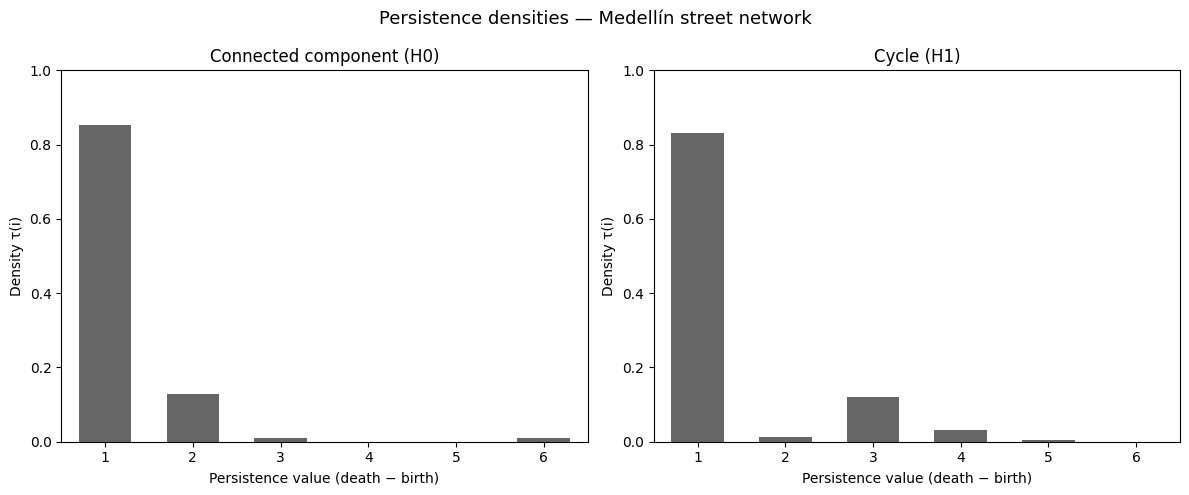

In [4]:
# -----------------------------
# PERSISTENCE DENSITY
# -----------------------------
def persistence_density(intervals, max_persistence=None):
    """
    Computes τ(i) = |{(p,q): (p,q) ∈ D, q-p = i}| / |D|
    for each integer persistence value i in [1, max_persistence].
    """
    finite = intervals[np.isfinite(intervals).all(axis=1)] if len(intervals) > 0 else np.empty((0, 2))
    if len(finite) == 0:
        return np.array([]), np.array([])

    lengths = (finite[:, 1] - finite[:, 0]).astype(int)
    total = len(finite)

    if max_persistence is None:
        max_persistence = int(lengths.max())
        print(max_persistence)

    i_values = np.arange(1, max_persistence + 1)
    density = np.array([np.sum(lengths == i) / total for i in i_values])
    return i_values, density


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (intervals, label, dim) in zip(axes, [
    (h0, "Connected component (H0)", "H0"),
    (h1, "Cycle (H1)",               "H1"),
]):
    i_vals, dens = persistence_density(intervals, max_persistence=None)
    if len(i_vals) == 0:
        ax.set_title(f"No finite {dim} intervals")
        continue
    ax.bar(i_vals, dens, color="#666666", width=0.6)
    ax.set_xlim(0.5, len(highway_order) - 0.5)
    ax.set_ylim(0, 1.0)
    ax.set_xticks(i_vals)
    ax.set_xlabel("Persistence value (death − birth)")
    ax.set_ylabel("Density τ(i)")
    ax.set_title(label)

plt.suptitle("Persistence densities — Medellín street network", fontsize=13)
plt.tight_layout()
plt.show()

In [5]:
from pathlib import Path
from shapely.geometry import Point

# -----------------------------
# BUILD SIMPLE UNDIRECTED GRAPH
# -----------------------------
H = nx.Graph()

for (u, v, k), row in edges.iterrows():
    hw = row["highway"]
    t = filtration_time[hw]

    if u == v:
        continue

    for n in (u, v):
        if not H.has_node(n):
            H.add_node(n, x=G.nodes[n]["x"], y=G.nodes[n]["y"])

    if H.has_edge(u, v):
        if t < H[u][v]["filtration"]:
            H[u][v]["filtration"] = t
            H[u][v]["geometry"] = row.geometry
        H[u][v]["highway_types"].add(hw)
    else:
        H.add_edge(
            u, v,
            filtration=t,
            highway_types={hw},
            geometry=row.geometry,
        )

print("Final graph summary")
print("Nodes:", H.number_of_nodes())
print("Edges:", H.number_of_edges())


Final graph summary
Nodes: 29392
Edges: 36331


In [43]:
import geopandas as gpd
def export_filtration_pdfs(H, highway_order, bounds, crs, out_dir="homology_graph_exports"):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    xmin, ymin, xmax, ymax = bounds

    for t, hw in enumerate(highway_order):
        H_t = nx.Graph()
        H_t.add_nodes_from((n, d.copy()) for n, d in H.nodes(data=True))
        H_t.add_edges_from(
            (u, v, d.copy())
            for u, v, d in H.edges(data=True)
            if d["filtration"] <= t
        )
        H_t.remove_nodes_from(list(nx.isolates(H_t)))

        edge_rows = [
            {
                "u": u,
                "v": v,
                "filtration": d["filtration"],
                "highway_types": ",".join(sorted(d["highway_types"])),
                "geometry": d["geometry"],
            }
            for u, v, d in H_t.edges(data=True)
        ]
        node_rows = [
            {"node": n, "geometry": Point(d["x"], d["y"])}
            for n, d in H_t.nodes(data=True)
        ]

        edges_gdf_t = gpd.GeoDataFrame(edge_rows, geometry="geometry", crs=crs)
        nodes_gdf_t = gpd.GeoDataFrame(node_rows, geometry="geometry", crs=crs)

        fig, ax = plt.subplots(figsize=(12, 12))
        if not edges_gdf_t.empty:
            edges_gdf_t.plot(ax=ax, linewidth=0.35, color="black")
        if not nodes_gdf_t.empty:
            nodes_gdf_t.plot(ax=ax, markersize=1, color="crimson")

        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.set_axis_off()
        ax.set_title(f"Step {t}: {' + '.join(highway_order[:t+1])}")

        fig.savefig(out_dir / f"step_{t:02d}_{hw}.pdf", bbox_inches="tight")
        plt.close(fig)

export_filtration_pdfs(H, highway_order, (xmin, ymin, xmax, ymax), edges.crs)
